# 01 — Le corpus de comptines

Objectif du projet : un petit GPT caractère, comme celui de la séance 2,
qui écrit une **comptine anglaise** à partir de quelques mots qu'on lui
donne (`cat, moon` → une comptine qui parle d'un chat et de la lune).

Avant tout modèle, il faut des données. Ce notebook :

1. télécharge des recueils de comptines du domaine public (Project Gutenberg) ;
2. les nettoie et les découpe en comptines individuelles ;
3. regarde ce qu'on a obtenu (taille, vocabulaire, mots fréquents) ;
4. définit le **format d'un exemple d'entraînement** : les mots-clés, puis la comptine ;
5. sépare train / validation et sauvegarde le corpus pour le notebook 02.

In [1]:
import random
import re
import urllib.request
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

In [2]:
SEED = 1337
random.seed(SEED)

try:
    ROOT = Path(__file__).resolve().parent
except NameError:  # exécution dans une cellule Jupyter : `__file__` n'existe pas
    ROOT = Path.cwd()

DATA_DIR = ROOT / "data"
RAW_DIR = DATA_DIR / "raw"
TRAIN_PATH = DATA_DIR / "comptines_train.txt"
VAL_PATH = DATA_DIR / "comptines_val.txt"
GUTENBERG_URL = "https://www.gutenberg.org/cache/epub/{id}/pg{id}.txt"

# Recueils de comptines (nursery rhymes) du Project Gutenberg : numéro → titre.
BOOKS = {
    10607: "The Real Mother Goose",
    39784: "Mother Goose's Nursery Rhymes",
    26197: "The Nursery Rhyme Book",
    32415: "The Nursery Rhymes of England",
    61009: "Our Old Nursery Rhymes",
    38562: "The Big Book of Nursery Rhymes",
    23794: "Mother Goose or the Old Nursery Rhymes",
    20511: "The Little Mother Goose",
    24623: "Mother Goose",
    18546: "Denslow's Mother Goose",
    28687: "The Only True Mother Goose Melodies",
    76703: "Sing-song: A nursery rhyme book",
}

## 1. Télécharger les livres

Comme `input.txt` pour Shakespeare au script 06 : on ne télécharge un livre
que s'il n'est pas déjà sur le disque.

In [3]:
RAW_DIR.mkdir(parents=True, exist_ok=True)
books = {}
for book_id, title in BOOKS.items():
    path = RAW_DIR / f"{book_id}.txt"
    if not path.exists():
        urllib.request.urlretrieve(GUTENBERG_URL.format(id=book_id), path)
    books[book_id] = path.read_text(encoding="utf-8")
    print(f"{book_id:>6}  {len(books[book_id]):>8,} caractères   {title}")

 10607   105,782 caractères   The Real Mother Goose
 39784   137,621 caractères   Mother Goose's Nursery Rhymes
 26197   201,636 caractères   The Nursery Rhyme Book
 32415   306,471 caractères   The Nursery Rhymes of England
 61009    35,950 caractères   Our Old Nursery Rhymes
 38562   131,862 caractères   The Big Book of Nursery Rhymes
 23794    29,922 caractères   Mother Goose or the Old Nursery Rhymes
 20511   120,999 caractères   The Little Mother Goose
 24623    60,590 caractères   Mother Goose
 18546    29,232 caractères   Denslow's Mother Goose
 28687    71,959 caractères   The Only True Mother Goose Melodies
 76703    51,025 caractères   Sing-song: A nursery rhyme book


## 2. Nettoyer

Un fichier Gutenberg, ce n'est pas que le livre :

- un **en-tête** et un **pied de page** de licence, entre les balises
  `*** START OF ...` et `*** END OF ...` : on ne garde que le milieu ;
- des **illustrations** notées `[Illustration: ...]` et de l'italique noté
  `_comme ceci_` : on les retire ;
- de la **typographie** : guillemets courbes, tirets longs. Pour un modèle
  caractère, `'` et `’` sont deux caractères différents qui veulent dire la
  même chose : on ramène tout à l'ASCII. Le vocabulaire est plus petit, et
  chaque caractère a plus d'exemples pour être appris.

In [4]:
TYPO = {"’": "'", "‘": "'", "“": '"', "”": '"', "—": "--", "–": "-", " ": " "}


def strip_gutenberg(text: str) -> str:
    """Garde le texte entre les balises START et END de Gutenberg."""
    start = re.search(r"\*\*\* ?START OF.*?\*\*\*", text)
    end = re.search(r"\*\*\* ?END OF", text)
    return text[start.end() if start else 0 : end.start() if end else len(text)]


def clean(text: str) -> str:
    """Retire illustrations et italique, ramène la typographie à l'ASCII."""
    text = text.replace("\r\n", "\n")
    for fancy, plain in TYPO.items():
        text = text.replace(fancy, plain)
    text = re.sub(r"\[Illustration[^\]]*\]", "\n\n", text, flags=re.S)  # une illustration sépare deux blocs
    text = re.sub(r"\[[^\]]*\]", "", text)  # notes entre crochets
    text = text.replace("_", "")  # _italique_
    return text.encode("ascii", errors="ignore").decode()  # ce qui reste hors ASCII disparaît


cleaned = {book_id: clean(strip_gutenberg(text)) for book_id, text in books.items()}
start = cleaned[10607].find("BOY AND THE SPARROW", 10_000)  # après le sommaire
print(cleaned[10607][start : start + 600])

BOY AND THE SPARROW

A little cock-sparrow sat on a green tree,
And he chirruped, he chirruped, so merry was he;
A naughty boy came with his wee bow and arrow,
Determined to shoot this little cock-sparrow.

"This little cock-sparrow shall make me a stew,
And his giblets shall make me a little pie, too."
"Oh, no," says the sparrow "I won't make a stew."
So he flapped his wings and away he flew.


OLD WOMAN, OLD WOMAN

There was an old woman tossed in a basket,
  Seventeen times as high as the moon;
But where she was going no mortal could tell,
  For under her arm she carried a broom.

"Old woma


## 3. Découper en comptines

Chaque livre a sa propre mise en page : sommaires, préfaces en prose,
titres en majuscules, vers indentés… Plutôt qu'un découpage par livre, une
règle commune :

- on coupe le texte en **blocs** séparés par une ligne vide (une strophe,
  un titre, un paragraphe) ;
- on garde un bloc s'il **ressemble à des vers** :
  - entre 2 et 12 lignes ;
  - des lignes courtes (≤ 60 caractères) : la prose, elle, remplit la ligne
    jusqu'à ~70 caractères ;
  - au moins 80 % des lignes commencent par une majuscule (début de vers) ;
  - pas de ligne tout en majuscules (titres), pas de chiffres (sommaires et
    numéros de page) ;
  - des lignes qui ne sont **pas rangées par ordre alphabétique** : plusieurs
    recueils finissent par un index des premiers vers, qui ressemble à
    s'y méprendre à des vers (courts, avec une majuscule), mais trié de A à Z ;
  - une dernière ligne qui finit par une **ponctuation** : une strophe se
    termine par `.`, `!`, `?`… alors qu'une ligne d'index s'arrête sur un mot ;
  - au moins 8 mots.

Une comptine de plusieurs strophes donne donc plusieurs exemples : ce n'est
pas un problème, une strophe de nursery rhyme se tient souvent seule.

In [5]:
def looks_like_rhyme(lines: list[str]) -> bool:
    """Vrai si le bloc de lignes ressemble à une strophe de comptine."""
    if not 2 <= len(lines) <= 12:
        return False
    if any(len(line) > 60 for line in lines):  # prose
        return False
    if any(re.search(r"\d|[{}*=]|Gutenberg|CONTENTS|INDEX", line) for line in lines):  # sommaires, licence
        return False
    if any(line.isupper() for line in lines):  # titres
        return False
    if lines[-1][-1].isalpha():  # une strophe finit par une ponctuation, une ligne d'index non
        return False
    if sum(line[0].isupper() or line[0] in "\"'(" for line in lines) / len(lines) < 0.8:
        return False
    keys = [re.sub(r"[^a-z]", "", line.lower()) for line in lines]  # l'index trie sur les lettres seules
    in_order = sum(a < b for a, b in zip(keys, keys[1:])) / (len(keys) - 1)
    if len(lines) >= 5 and in_order >= 0.8:  # index alphabétique des premiers vers
        return False
    return len(re.findall(r"[a-zA-Z]+", " ".join(lines))) >= 8


def extract_rhymes(text: str) -> list[str]:
    """Toutes les strophes d'un livre nettoyé, une chaîne par strophe."""
    rhymes = []
    for block in re.split(r"\n\s*\n", text):
        lines = [line.strip() for line in block.split("\n") if line.strip()]  # on retire l'indentation
        if looks_like_rhyme(lines):
            rhymes.append("\n".join(lines))
    return rhymes


for rhyme in extract_rhymes(cleaned[10607])[:3]:
    print(rhyme, end="\n\n")

Little Bo-Peep has lost her sheep,
And can't tell where to find them;
Leave them alone, and they'll come home,
And bring their tails behind them.

Little Bo-Peep fell fast asleep,
And dreamt she heard them bleating;
But when she awoke, she found it a joke,
For still they all were fleeting.

Then up she took her little crook,
Determined for to find them;
She found them indeed, but it made her heart bleed,
For they'd left all their tails behind 'em!



Les mêmes comptines reviennent d'un recueil à l'autre (*Jack and Jill* est
dans presque tous). Un doublon, c'est un exemple que le modèle voit deux fois
plus que les autres, et, s'il tombe à la fois dans le train et dans la
validation, une validation qui mesure de la récitation. On **dédoublonne** en
comparant les textes sans ponctuation ni majuscules.

In [6]:
rhymes, seen, per_book = [], set(), Counter()
for book_id, text in cleaned.items():
    for rhyme in extract_rhymes(text):
        key = re.sub(r"[^a-z]", "", rhyme.lower())  # "Jack and Jill," == "jack and jill"
        if key not in seen:
            seen.add(key)
            rhymes.append(rhyme)
            per_book[book_id] += 1

for book_id, n in per_book.most_common():
    print(f"{n:>5} comptines   {BOOKS[book_id]}")
print(f"\ntotal : {len(rhymes):,} comptines, {sum(len(r) for r in rhymes):,} caractères")

  692 comptines   The Nursery Rhymes of England
  474 comptines   Mother Goose's Nursery Rhymes
  440 comptines   The Real Mother Goose
  348 comptines   The Big Book of Nursery Rhymes
  286 comptines   The Nursery Rhyme Book
  248 comptines   The Little Mother Goose
  196 comptines   Sing-song: A nursery rhyme book
  149 comptines   The Only True Mother Goose Melodies
   67 comptines   Mother Goose
   31 comptines   Mother Goose or the Old Nursery Rhymes
   26 comptines   Denslow's Mother Goose
   24 comptines   Our Old Nursery Rhymes

total : 2,981 comptines, 408,091 caractères


In [7]:
for rhyme in random.sample(rhymes, 4):
    print(rhyme, end="\n\n")

The three little kittens they washed their mittens,
And hung them up to dry;
"Oh! mammy dear,
Look here, look here,
Our mittens we have wash'd."
"What! wash'd your mittens,
You darling kittens!
But I smell a rat close by!
Hush! hush!" Miew, miew,
Miew, miew, miew, miew.

Little Robin Redbreast sat upon a tree;
Up went Pussy cat and down went he.
Down came Pussy cat, and away Robin ran;
Says little Robin Redbreast: "Catch me if you can."

When the cows come home the milk is coming,
Honey's made while the bees are humming;
Duck and drake on the rushy lake,
And the deer live safe in the breezy brake;
And timid, funny, brisk little bunny,
Winks his nose and sits all sunny.

Made in London,
Sold at York,
Stops a bottle
And is a cork.



## 4. Ce qu'on a obtenu

**Taille.** Autour de 400 000 caractères : moins de la moitié de Tiny
Shakespeare (1,1 million). C'est petit pour un modèle de langue, et c'est un
point à surveiller : le modèle risque de réciter son corpus plus tôt
(on regardera l'écart train / validation au notebook 02).

**Vocabulaire caractère.** Comme au script 01 : l'ensemble des caractères
distincts. Grâce au nettoyage, il est proche de celui de Shakespeare.

In [8]:
all_text = "\n\n".join(rhymes)
chars = sorted(set(all_text))
print(f"vocab_size : {len(chars)}")
print(repr("".join(chars)))

vocab_size : 66
'\n !"&\'(),-.:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz'


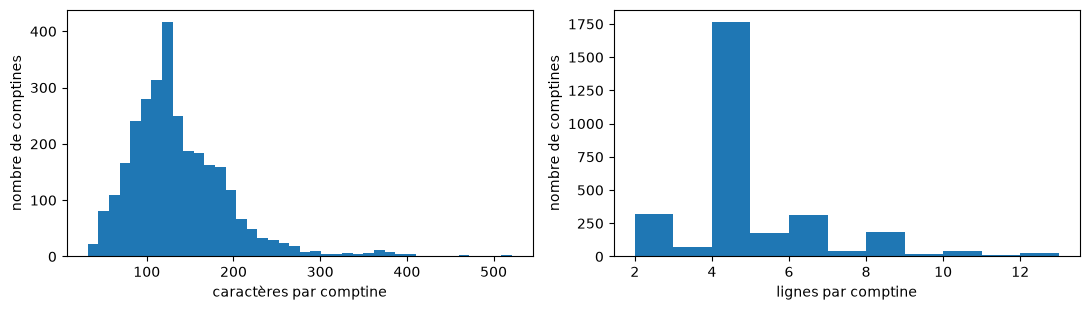

longueur médiane : 125 caractères   max : 521
comptines de moins de 230 caractères : 94.2%


In [9]:
lengths = [len(r) for r in rhymes]
n_lines = [r.count("\n") + 1 for r in rhymes]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].hist(lengths, bins=40)
axes[0].set_xlabel("caractères par comptine")
axes[1].hist(n_lines, bins=range(2, 14))
axes[1].set_xlabel("lignes par comptine")
for ax in axes:
    ax.set_ylabel("nombre de comptines")
plt.tight_layout()
plt.show()
print(f"longueur médiane : {sorted(lengths)[len(lengths) // 2]} caractères   max : {max(lengths)}")
print(f"comptines de moins de 230 caractères : {sum(n <= 230 for n in lengths) / len(lengths):.1%}")

La longueur compte pour le choix de `block_size` (la fenêtre de contexte) au
notebook 02 : le modèle doit voir **les mots-clés et toute la comptine** en
même temps, sinon il oublie les mots-clés avant la fin. Une fenêtre de 256
caractères couvre la très grande majorité des comptines.

## 5. Les mots-clés

Le corpus ne contient que des comptines, pas de couples « mots → comptine ».
On les **fabrique** : pour chaque comptine, on tire au hasard quelques mots
qu'elle contient, et on apprend au modèle à écrire la comptine *à partir
de ces mots*.

Quels mots ? Pas `the`, `and`, `she` : ils sont partout et ne disent rien du
sujet. Ce sont les **stop words** ; scikit-learn en fournit une liste pour
l'anglais (`ENGLISH_STOP_WORDS`). On garde les autres mots d'au moins 3
lettres : `cat`, `moon`, `kettle`, `jump`…

In [10]:
def content_words(rhyme: str) -> list[str]:
    """Les mots porteurs de sens d'une comptine, sans doublon, dans l'ordre."""
    words = re.findall(r"[a-z]+", rhyme.lower())
    return list(dict.fromkeys(w for w in words if len(w) >= 3 and w not in ENGLISH_STOP_WORDS))


example = next(r for r in rhymes if r.startswith("Polly put the kettle on"))
print(example)
print("\n→", content_words(example))

Polly put the kettle on,
Polly put the kettle on,
Polly put the kettle on,
We'll all have tea.

→ ['polly', 'kettle', 'tea']


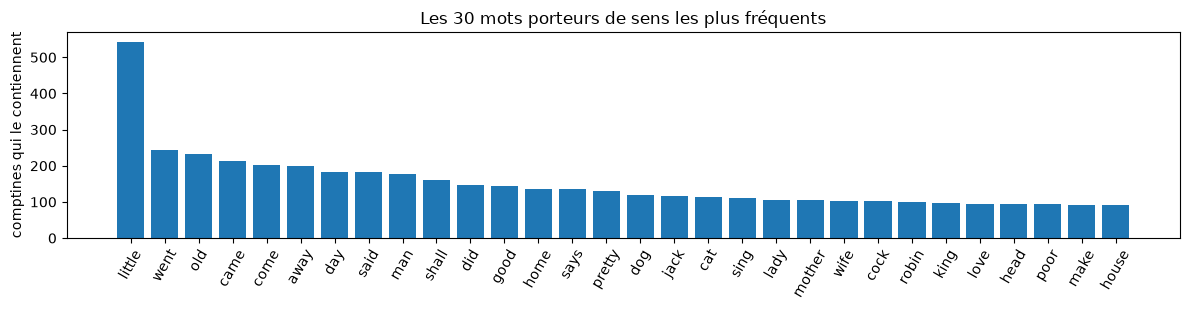

little, went, old, came, come, away, day, said, man, shall, did, good, home, says, pretty, dog, jack, cat, sing, lady, mother, wife, cock, robin, king, love, head, poor, make, house
4,735 mots distincts ; 1,381 apparaissent dans au moins 5 comptines


In [11]:
word_counts = Counter(w for r in rhymes for w in content_words(r))
top = word_counts.most_common(30)
plt.figure(figsize=(12, 3.2))
plt.bar([w for w, _ in top], [c for _, c in top])
plt.xticks(rotation=60)
plt.ylabel("comptines qui le contiennent")
plt.title("Les 30 mots porteurs de sens les plus fréquents")
plt.tight_layout()
plt.show()
print(", ".join(w for w, _ in top))
print(f"{len(word_counts):,} mots distincts ; {sum(c >= 5 for c in word_counts.values()):,} apparaissent dans au moins 5 comptines")

Ce graphique dit quels mots le modèle **connaîtra bien** : `king`, `cat`,
`little`, `pretty`… Un mot qui n'apparaît que dans une ou deux comptines (ou
jamais) sera recopié par le modèle, mais il ne saura pas quoi en faire.

### Le format d'un exemple

Un modèle caractère ne voit qu'une suite de caractères : les mots-clés font
donc partie du texte. Chaque exemple d'entraînement a cette forme :

```
words: kettle, tea
Polly put the kettle on,
...
We'll all have tea.

```

- une première ligne `words: ...` : la **consigne** ;
- la comptine ;
- une **ligne vide** pour finir. Aucune comptine ne contient de ligne vide :
  quand le modèle en écrit une, la comptine est terminée et on arrête la
  génération.

Le modèle apprend à prédire le caractère suivant sur tout le texte, comme au
script 06. À la génération, on lui donne seulement `words: cat, moon\n` et il
écrit la suite : la comptine qui va avec ces mots.

On tirera **de nouveaux mots-clés à chaque fois** qu'une comptine passe à
l'entraînement (notebook 02) : une même comptine sert avec `kettle, tea`,
puis `polly`, puis `tea, polly, kettle`… Le modèle ne peut pas apprendre par
cœur une consigne fixe : il doit apprendre que les mots donnés **doivent
apparaître** dans ce qu'il écrit.

In [12]:
def make_example(rhyme: str, max_keywords: int = 3) -> str:
    """Un exemple d'entraînement : mots-clés tirés au hasard, comptine, ligne vide."""
    words = content_words(rhyme)
    keywords = random.sample(words, k=random.randint(1, min(max_keywords, len(words)))) if words else []
    return f"words: {', '.join(keywords)}\n{rhyme}\n\n"


for _ in range(3):
    print(repr(make_example(example)))

"words: tea, polly, kettle\nPolly put the kettle on,\nPolly put the kettle on,\nPolly put the kettle on,\nWe'll all have tea.\n\n"
"words: tea, kettle\nPolly put the kettle on,\nPolly put the kettle on,\nPolly put the kettle on,\nWe'll all have tea.\n\n"
"words: kettle, polly\nPolly put the kettle on,\nPolly put the kettle on,\nPolly put the kettle on,\nWe'll all have tea.\n\n"


## 6. Train / validation et sauvegarde

Au script 01, on coupait le texte à 90 % : la validation était la fin de la
pièce. Ici, on coupe **par comptine** : 90 % des comptines pour
l'entraînement, 10 % pour la validation, tirées au hasard (les recueils
sont rangés par livre, couper à 90 % mettrait tout *Sing-song* en
validation).

On sauvegarde les comptines **sans** les mots-clés, une ligne vide entre
deux comptines : les mots-clés seront tirés au moment de l'entraînement.

In [13]:
shuffled = rhymes[:]
random.shuffle(shuffled)
n = int(0.9 * len(shuffled))
train_rhymes, val_rhymes = shuffled[:n], shuffled[n:]

TRAIN_PATH.write_text("\n\n".join(train_rhymes), encoding="utf-8")
VAL_PATH.write_text("\n\n".join(val_rhymes), encoding="utf-8")
print(f"train : {len(train_rhymes):,} comptines → {TRAIN_PATH.relative_to(ROOT)}")
print(f"val   : {len(val_rhymes):,} comptines → {VAL_PATH.relative_to(ROOT)}")

train : 2,682 comptines → data\comptines_train.txt
val   : 299 comptines → data\comptines_val.txt


Le notebook 02 relit ces deux fichiers : `text.split("\n\n")` redonne la
liste des comptines.